<a href="https://colab.research.google.com/github/arupdey-data/house_price_prediction/blob/main/heart_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A project that will predict heart diease.


In [ ]:
import pandas as pd
df=pd.read_csv('synthetic_heart_disease.csv')

In [ ]:
print("\n--TOP 5 ROWS OF THE DATASET--")
df.head()


--TOP 5 ROWS OF THE DATASET--


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar_gt_120,resting_ecg,max_heart_rate,exercise_induced_angina,oldpeak,st_slope,num_major_vessels,thalassemia,heart_disease
0,33,1,0,90,175,0,0,135,1,1.6,1,2,2,1
1,66,1,0,110,238,1,1,103,0,0.6,1,1,2,1
2,61,1,0,102,205,0,0,118,1,1.3,0,0,3,1
3,50,0,0,93,203,0,1,149,1,5.7,1,0,2,1
4,50,0,2,110,250,0,1,127,0,1.7,1,1,2,0


In [ ]:
print("INFORMATIONS RELATED TO THE DATASET")
df.info()

INFORMATIONS RELATED TO THE DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         500 non-null    int64  
 1   sex                         500 non-null    int64  
 2   chest_pain_type             500 non-null    int64  
 3   resting_blood_pressure      500 non-null    int64  
 4   cholesterol                 500 non-null    int64  
 5   fasting_blood_sugar_gt_120  500 non-null    int64  
 6   resting_ecg                 500 non-null    int64  
 7   max_heart_rate              500 non-null    int64  
 8   exercise_induced_angina     500 non-null    int64  
 9   oldpeak                     500 non-null    float64
 10  st_slope                    500 non-null    int64  
 11  num_major_vessels           500 non-null    int64  
 12  thalassemia                 500 non-null    int64  
 13 

In [ ]:
print("Number of null values present in the dataset")
print(df.isnull().sum().sum())

Number of null values present in the dataset
0


In [ ]:
print(" Counts the occurrences of each unique value in the target variable (heart_disease), which helps you check for class imbalance ")
print(df['heart_disease'].value_counts())

 Counts the occurrences of each unique value in the target variable (heart_disease), which helps you check for class imbalance 
heart_disease
0    281
1    219
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('heart_disease', axis=1)
y = df['heart_disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(y_train.value_counts())
print(y_test.value_counts())

heart_disease
0    225
1    175
Name: count, dtype: int64
heart_disease
0    56
1    44
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=2000)

# Train the model
model.fit(X_train, y_train)

# Predict on test data
y_pred = model.predict(X_test)

# Compare predictions with actual values
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(comparison.head(10))

   Actual  Predicted
0       1          1
1       0          0
2       1          0
3       0          0
4       0          0
5       1          1
6       0          0
7       0          1
8       1          0
9       1          0


Model Accuracy: 74.00%

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.75      0.80      0.78        56
           1       0.72      0.66      0.69        44

    accuracy                           0.74       100
   macro avg       0.74      0.73      0.73       100
weighted avg       0.74      0.74      0.74       100



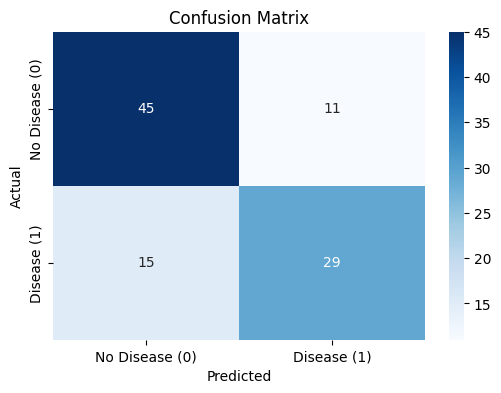

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calculate and print Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}\n")

# 2. Detailed Classification Report (Precision, Recall, F1-Score)
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 3. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease (0)', 'Disease (1)'],
            yticklabels=['No Disease (0)', 'Disease (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Train Random Forest
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train, y_train)

# 2. Evaluate
y_pred_rf = rf_model.predict(X_test)
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.2%}")
print(classification_report(y_test, y_pred_rf))


Random Forest Accuracy: 70.00%
              precision    recall  f1-score   support

           0       0.71      0.79      0.75        56
           1       0.68      0.59      0.63        44

    accuracy                           0.70       100
   macro avg       0.70      0.69      0.69       100
weighted avg       0.70      0.70      0.70       100



In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Scale the training and testing data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Re-train the Logistic Regression model
lr_scaled = LogisticRegression(max_iter=2000, random_state=42)
lr_scaled.fit(X_train_scaled, y_train)

# 3. Predict and Evaluate
y_pred_lr = lr_scaled.predict(X_test_scaled)
print(f"Scaled Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_lr):.2%}\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred_lr))


Scaled Logistic Regression Accuracy: 74.00%

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.75      0.80      0.78        56
           1       0.72      0.66      0.69        44

    accuracy                           0.74       100
   macro avg       0.74      0.73      0.73       100
weighted avg       0.74      0.74      0.74       100



/tmp/ipykernel_1175/1011600394.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='coolwarm')


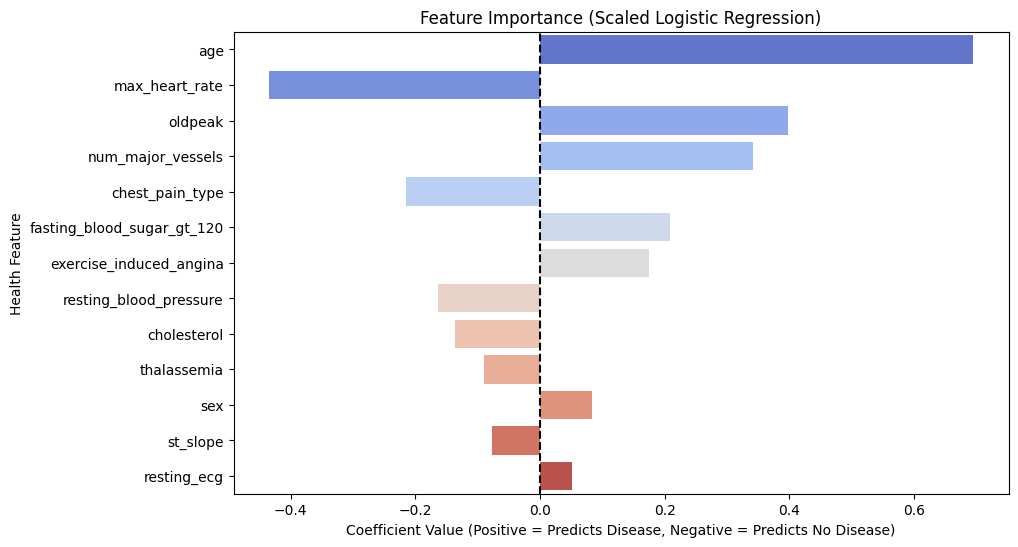

                       Feature  Importance
0                          age    0.694880
7               max_heart_rate   -0.435193
9                      oldpeak    0.398351
11           num_major_vessels    0.341004
2              chest_pain_type   -0.214987
5   fasting_blood_sugar_gt_120    0.207904
8      exercise_induced_angina    0.174215
3       resting_blood_pressure   -0.163740
4                  cholesterol   -0.136191
12                 thalassemia   -0.090372
1                          sex    0.083326
10                    st_slope   -0.076892
6                  resting_ecg    0.050767


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract coefficients from the scaled model
coefficients = lr_scaled.coef_[0]

# Create a DataFrame for visualization
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': coefficients
})

# Sort by absolute importance value
feature_importance['Abs_Importance'] = feature_importance['Importance'].abs()
feature_importance = feature_importance.sort_values(by='Abs_Importance', ascending=False)

# Plot the features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='coolwarm')
plt.title('Feature Importance (Scaled Logistic Regression)')
plt.xlabel('Coefficient Value (Positive = Predicts Disease, Negative = Predicts No Disease)')
plt.ylabel('Health Feature')
plt.axvline(x=0, color='black', linestyle='--')
plt.show()

# Print the values
print(feature_importance[['Feature', 'Importance']])


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize the SVM Classifier (using RBF kernel by default)
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)

# 2. Train using the SCALED data (SVMs strictly require scaled data!)
svm_model.fit(X_train_scaled, y_train)

# 3. Predict and Evaluate
y_pred_svm = svm_model.predict(X_test_scaled)
print(f"SVM Classifier Accuracy: {accuracy_score(y_test, y_pred_svm):.2%}\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred_svm))


SVM Classifier Accuracy: 71.00%

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.73      0.77      0.75        56
           1       0.68      0.64      0.66        44

    accuracy                           0.71       100
   macro avg       0.71      0.70      0.70       100
weighted avg       0.71      0.71      0.71       100



In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Get predicted probabilities instead of hard 0s and 1s
# Column 1 represents the probability of having heart disease (Class 1)
y_prob_lr = lr_scaled.predict_proba(X_test_scaled)[:, 1]

# 2. Lower the threshold from 0.5 to 0.4
custom_threshold = 0.4
y_pred_custom = (y_prob_lr >= custom_threshold).astype(int)

# 3. Evaluate the new threshold
print(f"--- Evaluation at Threshold: {custom_threshold} ---")
print(f"New Accuracy: {accuracy_score(y_test, y_pred_custom):.2%}\n")
print(classification_report(y_test, y_pred_custom))

# 4. Compare confusion matrices to see how many lives were saved
cm_old = confusion_matrix(y_test, y_pred_lr)
cm_new = confusion_matrix(y_test, y_pred_custom)

print(f"Old False Negatives (Missed Patients at 0.5): {cm_old[1, 0]}")
print(f"New False Negatives (Missed Patients at {custom_threshold}): {cm_new[1, 0]}")


--- Evaluation at Threshold: 0.4 ---
New Accuracy: 72.00%

              precision    recall  f1-score   support

           0       0.80      0.66      0.73        56
           1       0.65      0.80      0.71        44

    accuracy                           0.72       100
   macro avg       0.73      0.73      0.72       100
weighted avg       0.74      0.72      0.72       100

Old False Negatives (Missed Patients at 0.5): 15
New False Negatives (Missed Patients at 0.4): 9
